# Task: Predictive Incident Detection

## Контекст
Мы логируем события сетевой активности и транзакций. Наша цель — предиктивная детекция инцидентов.
**Инцидент — это не одно событие, а логическая цепочка (сессия) связанных действий.**
Инциденты могут пересекаться по времени (параллельные атаки на разные сущности).

## Данные
*   `events_log.parquet` — сырой лог (~1.5 млн строк). Содержит `event_id`, `timestamp`, и признаки (в основном категориальные: IP, GEO, OS, Device, Action, Status и др.).
*   `incidents_labels.csv` — историческая разметка. Содержит `incident_id`, `incident_type`, и список `event_ids`, входящих в инцидент.

In [1]:
!ls

"ls" �� ���� ����७��� ��� ���譥�
��������, �ᯮ��塞�� �ணࠬ��� ��� ������ 䠩���.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_curve, f1_score, classification_report, auc
from catboost import CatBoostClassifier, Pool

import warnings
warnings.filterwarnings('ignore')

In [3]:
events_df = pd.read_parquet('events_log.parquet')
print(events_df.head())

                               event_id                  timestamp  \
0  28a0c1c1-0826-4b7c-be39-1bc38c656c46 2023-11-01 00:00:01.438456   
1  39ec0c47-731f-4fa8-a7c4-c5e4da12a228 2023-11-01 00:00:02.421655   
2  4cae959e-b16b-4e47-a639-3dcce5619286 2023-11-01 00:00:02.611185   
3  a86873bb-88d2-4a1c-a83d-244d6bd830ec 2023-11-01 00:00:03.677816   
4  3c644a3e-f49d-4884-94e2-7ab3dc042fb2 2023-11-01 00:00:06.405153   

            src_ip          dst_ip    user_id  \
0   68.179.252.112     62.73.42.17  USR_99658   
1    36.152.191.52  65.117.151.132  USR_74049   
2   106.181.66.229  27.227.230.149  USR_33558   
3   127.43.241.190  195.233.210.31  USR_23534   
4  189.232.146.218     85.0.205.74  USR_42160   

                             session_id src_geo dst_geo device_type  \
0  0e8987f9-15b4-4e2a-a9d1-0664b8bf363a      KR      KR      iPhone   
1  1c675572-5fe3-4683-baea-d62eb093b111      US      KR  Desktop-PC   
2  32858b44-727d-4020-9579-6e46cde5d835      BR      JP      iPhone   


In [4]:
events_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1521732 entries, 0 to 1521731
Data columns (total 15 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   event_id           1521732 non-null  str           
 1   timestamp          1521732 non-null  datetime64[ns]
 2   src_ip             1521732 non-null  str           
 3   dst_ip             1521732 non-null  str           
 4   user_id            1521732 non-null  str           
 5   session_id         1521732 non-null  str           
 6   src_geo            1521732 non-null  str           
 7   dst_geo            1521732 non-null  str           
 8   device_type        1521732 non-null  str           
 9   os                 1521732 non-null  str           
 10  protocol           1521732 non-null  str           
 11  action_type        1521732 non-null  str           
 12  status_code        1521732 non-null  int64         
 13  payload_size       1521732 non-null  i

In [5]:
incidents_df = pd.read_csv('incidents_labels.csv')
print(incidents_df.head())

                            incident_id incident_type  \
0  af399196-871f-4474-b100-ffe5de9788e3        Type_1   
1  2eea603e-a2fb-4c99-a76a-126854384322        Type_1   
2  f5e987ee-cab8-4adc-a378-b566e48933d9        Type_1   
3  fd05896a-02f5-4e78-8bf0-6223be1a20a3        Type_1   
4  48863042-9135-4b00-9902-ed2b3b1827b5        Type_1   

                                           event_ids  
0  c0ecea01-ea82-48dc-8d41-3a356de30fb0,e07a5e8e-...  
1  418613ae-a731-4859-8b7f-d9bf90bef2a2,56d6eb89-...  
2  0dd6489f-8584-4563-bb67-312295ba15ef,c7c5c094-...  
3  4587216d-3b13-4512-b508-bdb65ee88bc2,288f0455-...  
4  eff8a594-1e12-4ba1-b279-59895edca961,8c5f3e13-...  


In [6]:
incidents_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1036 entries, 0 to 1035
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   incident_id    1036 non-null   str  
 1   incident_type  1036 non-null   str  
 2   event_ids      1036 non-null   str  
dtypes: str(3)
memory usage: 676.6 KB


In [7]:
#Преобразование колонки events_ids в список
incidents_df['events_ids_list'] = incidents_df['event_ids'].apply(lambda x: x.split(','))

In [8]:
#Собираем set(), состоящий из event_id, которые являются инцидентами
incident_event_ids = set()
for ids in incidents_df['events_ids_list']:
    incident_event_ids.update(ids)

In [9]:
#Создаем разметку target
events_df['target'] = events_df['event_id'].isin(incident_event_ids).astype(int)

In [10]:
print(f'Общее количество событий: {len(events_df)}')
print(f"Количество инцидентов: {events_df['target'].sum()}")

Общее количество событий: 1521732
Количество инцидентов: 16902


In [11]:
#Сортируем по времени события
events_df = events_df.sort_values('timestamp').reset_index(drop=True)

In [12]:
#Создаем базовые фичи времени
events_df['hour'] = events_df['timestamp'].dt.hour
events_df['dayofweek'] = events_df['timestamp'].dt.dayofweek
events_df['is_weekend'] = events_df['dayofweek'].isin([5,6]).astype(int)

In [25]:
#Определяем категориальыне фичи
cat_features = [col for col in events_df.columns if events_df[col].dtype in ['str', 'string'] and col not in ['event_id', 'user_id', 'session_id']]
print(f"Категориальные признаки: {cat_features}")

Категориальные признаки: ['src_ip', 'dst_ip', 'src_geo', 'dst_geo', 'device_type', 'os', 'protocol', 'action_type', 'resource_accessed']


In [28]:
#Разделяем датасет на данные и target (X и y)
drop_cols = ['event_id', 'timestamp', 'target', 'user_id', 'session_id']

X = events_df.drop(columns=[col for col in drop_cols if col in events_df.columns])
y = events_df['target']

In [29]:
#Делим данные по времени
split_idx = int(len(events_df) * 0.8)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

In [30]:
print(f'Обучающая выборка: {X_train.shape}')
print(f'Тестовая выборка: {X_test.shape}')

Обучающая выборка: (1217385, 14)
Тестовая выборка: (304347, 14)


In [31]:
#Создаем Pool для CatBoost
train_pool = Pool(X_train, y_train, cat_features=cat_features)
test_pool = Pool(X_test, y_test, cat_features=cat_features)

In [38]:
#Обучаем модель CatBoost
model_cb = CatBoostClassifier(
    iterations = 500, 
    depth = 6,
    learning_rate = 0.1,
    auto_class_weights='Balanced', #Подбор весов обратно пропорционально частоте классов
    eval_metric='PRAUC',
    random_seed=42,
    verbose=30, #Вывод метрики каждые 10 шагов
    early_stopping_rounds=100
)

In [43]:
model_cb.fit(train_pool, eval_set=test_pool, use_best_model=True, plot = True)

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

0:	learn: 0.9957148	test: 0.6820086	best: 0.6820086 (0)	total: 4.92s	remaining: 40m 53s
30:	learn: 0.9989267	test: 0.6650662	best: 0.6847708 (3)	total: 1m 18s	remaining: 19m 52s
60:	learn: 0.9991012	test: 0.6571333	best: 0.6847708 (3)	total: 2m 31s	remaining: 18m 13s
90:	learn: 0.9992106	test: 0.6596810	best: 0.6847708 (3)	total: 3m 49s	remaining: 17m 10s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.6847707563
bestIteration = 3

Shrink model to first 4 iterations.


CatBoostClassifier(auto_class_weights='Balanced', depth=6, early_stopping_rounds=100, eval_metric='PRAUC', iterations=500, learning_rate=0.1, random_seed=42, verbose=30)

In [44]:
#Оценка качества 
y_pred_proba = model_cb.predict_proba(X_test)[:, 1]

In [45]:
#PR-AUC
precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
pr_auc = auc(recall, precision)

print(f"\nPR-AUC: {pr_auc:.4f}")


PR-AUC: 0.1867


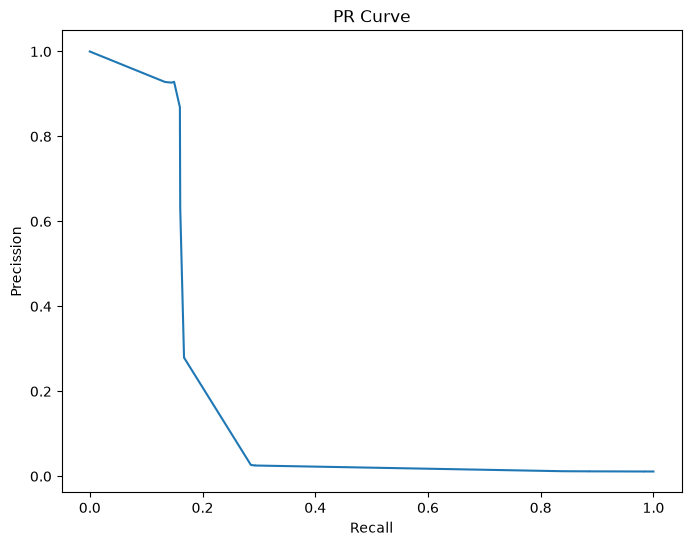

In [46]:
#Визуализация PR-кривой
plt.figure(figsize=(8,6))
plt.plot(recall, precision, label = f'PR curve (area = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precission')
plt.title('PR Curve')
plt.show()

In [47]:
#Feature importance
feature_importance = model_cb.get_feature_importance(train_pool)
features_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': feature_importance
}).sort_values(by='Importance', ascending=False)

print("\nТоп-10 важных фичей:")
print(features_df.head(10))


Топ-10 важных фичей:
        Feature    Importance
0        src_ip  8.992422e+01
8   status_code  4.794887e+00
7   action_type  4.758724e+00
9  payload_size  4.959867e-01
3       dst_geo  2.618350e-02
4   device_type  9.731598e-08
1        dst_ip  0.000000e+00
2       src_geo  0.000000e+00
5            os  0.000000e+00
6      protocol  0.000000e+00
